# Day 2 — The architecture: one belief, many owners

Yesterday there was one robot, one belief and one free energy. Today the belief is spread over
processes that never talk to each other. They only read and write a shared graph.

- **A. The shared graph.** Who may write what, and what is left when a process dies.
- **B. Agents that only read and write.** What has to cross the boundary: a mean is not enough.
- **C. One free energy, many owners.** When the sum of the agents' objectives is the global one,
  when it is not, and what the difference costs, in nats.
- **D. No thresholds.** A range gate against a precision that grows with range.
- **E. The gate that survives.** The one case where a precision provably cannot do the job.

Every part is small on purpose. The robot's real agents are C++ processes on a distributed graph,
but the questions are exactly these.

In [1]:
import sys
from pathlib import Path

LABS = Path.cwd() if (Path.cwd() / "toyworld").exists() else Path.cwd().parent
sys.path.insert(0, str(LABS))

import matplotlib.pyplot as plt
import numpy as np

from toyworld import Graph

rng = np.random.default_rng(0)

## A. The shared graph

`toyworld.Graph` holds nodes, and a tree of RT edges (parent → child, a pose and a covariance).
There are no messages between agents: all coordination is a read or a write on this object.

Two kinds of change are different kinds of belief revision:
- **structural**: a node or edge appears or disappears (the world contains something new, or no
  longer contains something);
- **non-structural**: an attribute or a pose changes (something known has moved).

### A1. Ownership

Each node has one owner, and only the owner may change it. That is what makes "one process per
factor" true at run time. Complete `write` and `delete` so that any other writer gets a
`PermissionError`, and so that each successful call is logged.

In [2]:
class OwnedGraph(Graph):
    """A Graph that enforces the contract: only a node's owner may change or delete it."""

    def __init__(self):
        super().__init__()
        self.log = []                                   # (kind, writer, node name)

    def create(self, writer, name, type, parent="world", pose=None, cov=None, **attrs):
        nid = self.add_node(name, type, parent=parent, pose=pose, cov=cov, owner=writer, **attrs)
        self.log.append(("structural", writer, name))
        return nid

    def write(self, writer, key, **attrs):
        n = self.node(key)
        if n.owner != writer:
            raise PermissionError(f"{writer} may not write {n.name}, owned by {n.owner}")
        self.update(key, **attrs)
        self.log.append(("non-structural", writer, n.name))

    def write_rt(self, writer, key, pose, cov=None):
        n = self.node(key)
        if n.owner != writer:
            raise PermissionError(f"{writer} may not move {n.name}, owned by {n.owner}")
        self.set_rt(self.parent(key), key, pose, cov)
        self.log.append(("non-structural", writer, n.name))

    def delete(self, writer, key):
        n = self.node(key)
        if n.owner != writer:
            raise PermissionError(f"{writer} may not delete {n.name}, owned by {n.owner}")
        name = n.name
        self.remove(key)
        self.log.append(("structural", writer, name))


g = OwnedGraph()
g.create("room_concept", "room_1", "room", pose=[0.0, 0.0, 0.0])
g.create("table_concept", "table_1", "object", parent="room_1", pose=[2.0, 1.0, 0.0], subtype="table", mu=2.0)
g.create("bottle_concept", "bottle_1", "object", parent="room_1", pose=[2.1, 1.1, 0.0], subtype="bottle")
g.write("table_concept", "table_1", mu=2.02)
try:
    g.write("bottle_concept", "table_1", mu=9.9)
    raise AssertionError("the bottle agent was allowed to write the table")
except PermissionError as e:
    print("refused:", e)
assert g.node("table_1").attrs["mu"] == 2.02
print(g)
print(g.log)

refused: bottle_concept may not write table_1, owned by table_concept
world [root]
  room_1 [room] (room_concept)
    table_1 [object] (table_concept)
    bottle_1 [object] (bottle_concept)
[('structural', 'room_concept', 'room_1'), ('structural', 'table_concept', 'table_1'), ('structural', 'bottle_concept', 'bottle_1'), ('non-structural', 'table_concept', 'table_1')]


Any pose is obtained by naming two frames and asking the graph:

In [3]:
print("bottle in the table's frame:", g.transform("table_1", "bottle_1"))

bottle in the table's frame: [0.1 0.1 0. ]


### A2. A factor nothing is minimising

The `bottle_concept` process crashes. It cannot clean up, so its node stays in the graph, it looks
like any other node, and it no longer answers to any evidence. From inside any single agent this
is indistinguishable from ordinary data.

Write `sweep(g, alive)`: a survivor removes every node whose owner is not in the set `alive`.
Nodes with no owner (the root) stay. Mind that removing a node also removes its subtree.

In [4]:
def sweep(g, alive):
    """Remove nodes whose owner is dead. Returns the names removed."""
    removed = []
    for n in list(g.nodes.values()):
        if n.id in g.nodes and n.owner and n.owner not in alive:
            removed.append(n.name)
            g.remove(n.id)
    return removed


print("swept:", sweep(g, alive={"room_concept", "table_concept"}))
assert [n.name for n in g.by_type("object")] == ["table_1"]

swept: ['bottle_1']


## B. Agents that only read and write

A robot drives along a corridor; everything here is one coordinate, $x$. The localiser publishes
its pose estimate, wrong by a **frame error** $\delta_t \sim \mathcal N(0, s^2)$, on the RT edge
world → robot, *with its covariance*. Each object agent sees its object relative to the robot with
noise $r$. Placing the sighting in the world uses the robot's published pose:

$$ z_{it} = \hat x_t + \text{rel}_{it} = \theta_i + \delta_t + \varepsilon_{it}, \qquad \varepsilon_{it}\sim\mathcal N(0,r). $$

The object agent never calls the localiser. It reads the edge.

### B1. The object agent

Complete `ObjectAgent.step`: read the robot's pose and variance from the graph, form $z$, and do
Day 1's Kalman update (precisions add) with noise $R = r + s^2$ if `use_cov`, or $R = r$ if the
agent ignores the published covariance. Write the new `mu` and `var` to its **own** node.

In [5]:
R_SIGHT, S_FRAME = 0.05 ** 2, 0.10 ** 2        # sighting noise r, frame error s^2 (m^2)
M0, P0 = 0.0, 10.0 ** 2                        # the class prior
THETA = np.array([1.0, 2.5, 4.0])              # true positions


def robot_belief(g):
    """What any agent can know about the robot: published pose and variance along x."""
    node = g.node("robot")
    return g.world_pose("robot")[0], g.rt[node.id][1].cov[0, 0]


class Localiser:
    name = "room_concept"

    def __init__(self, g, s2, rng):
        self.g, self.s2, self.rng = g, s2, rng
        g.create(self.name, "robot", "robot", pose=np.zeros(3), cov=np.eye(3) * s2)

    def step(self, x_true):
        err = self.rng.normal(0.0, np.sqrt(self.s2))
        self.g.write_rt(self.name, "robot", [x_true + err, 0.0, 0.0], np.eye(3) * self.s2)


class ObjectAgent:
    def __init__(self, g, label, r, use_cov):
        self.g, self.node, self.owner = g, label, f"{label}_concept"
        self.r, self.use_cov = r, use_cov
        g.create(self.owner, label, "object", pose=[M0, 0.0, 0.0], mu=M0, var=P0)

    def step(self, rel):
        attrs = self.g.node(self.node).attrs
        x_hat, var_x = robot_belief(self.g)
        z = x_hat + rel
        R = self.r + var_x if self.use_cov else self.r
        info = 1.0 / attrs["var"] + 1.0 / R
        mu = (attrs["mu"] / attrs["var"] + z / R) / info
        self.g.write(self.owner, self.node, mu=mu, var=1.0 / info)


def run_trial(rng, use_cov, frames=20):
    """One run, all coordination through the graph. Returns the published (mu, var) of each object."""
    g = OwnedGraph()
    loc = Localiser(g, S_FRAME, rng)
    agents = [ObjectAgent(g, f"obj{i}", R_SIGHT, use_cov) for i in range(len(THETA))]
    for _ in range(frames):
        x_true = rng.uniform(-3.0, 8.0)
        loc.step(x_true)
        for theta, agent in zip(THETA, agents):
            agent.step(theta - x_true + rng.normal(0.0, np.sqrt(R_SIGHT)))
    attrs = [g.node(a.node).attrs for a in agents]
    return np.array([a["mu"] for a in attrs]), np.array([a["var"] for a in attrs])


mu, var = run_trial(rng, use_cov=True)
print("published means:", np.round(mu, 3), " sd:", np.round(np.sqrt(var), 3))

published means: [1.039 2.52  4.028]  sd: [0.025 0.025 0.025]


### B2. Is the published covariance needed?

Over many runs, compute the mean NEES $(\mu_i-\theta_i)^2/\mathrm{var}_i$ with and without
`use_cov`. An honest belief gives 1. Before running: **how far off do you expect the agent that
ignores the published covariance to be?**

In [6]:
def mean_nees(rng, use_cov, trials=600):
    vals = []
    for _ in range(trials):
        mu, var = run_trial(rng, use_cov)
        vals.append((mu - THETA) ** 2 / var)
    return float(np.mean(vals))


NEES_USE, NEES_IGNORE = mean_nees(rng, True), mean_nees(rng, False)
print(f"NEES with the published covariance: {NEES_USE:.2f}   ignoring it: {NEES_IGNORE:.2f}"
      f"   predicted (r+s2)/r = {(R_SIGHT + S_FRAME) / R_SIGHT:.2f}")

NEES with the published covariance: 1.09   ignoring it: 5.57   predicted (r+s2)/r = 5.00


The agent that takes the published pose as truth is about five times over-confident in variance,
which is exactly $(r+s^2)/r$. The covariance on the edge is what lets another process use the
estimate as evidence rather than as ground truth. A mean alone is half a belief.

## C. One free energy, many owners

Stack the world's data. $z_t$ collects the sightings of one frame: all $n$ objects share that
frame's error, so once the error is integrated out, the noise of one frame has covariance

$$ C = r\,I + s^2\,\mathbf 1\mathbf 1^\top . $$

The global free energy of a Gaussian belief $q(\theta)=\mathcal N(\mu,\Sigma)$ is given below. Each
agent instead minimises its *own* objective over its own instance: Day 1's complexity and
accuracy, on its own sightings alone, with $R = r + s^2$.

### C1. Write the agent's free energy

$$ F_i(\mu_i,v_i) = \sum_t \tfrac12\Big[\frac{(z_{it}-\mu_i)^2+v_i}{R}+\ln 2\pi R\Big]
   + \mathrm{KL}\big[\mathcal N(\mu_i,v_i)\,\|\,\mathcal N(m_0,p_0)\big] $$

In [7]:
def kl_gauss_diag(mu, v, m0, p0):
    return 0.5 * ((v + (mu - m0) ** 2) / p0 - 1.0 + np.log(p0 / v))


def F_global(mu, Sigma, z, r, s2, m0=M0, p0=P0):
    """Free energy of q = N(mu, Sigma) against the true joint, frame errors integrated out."""
    n, frames = z.shape[1], z.shape[0]
    C = r * np.eye(n) + s2 * np.ones((n, n))
    Cinv, logdet = np.linalg.inv(C), np.linalg.slogdet(C)[1]
    data = 0.5 * sum((zt - mu) @ Cinv @ (zt - mu) for zt in z)
    data += 0.5 * frames * (np.trace(Cinv @ Sigma) + logdet + n * np.log(2 * np.pi))
    complexity = 0.5 * ((np.trace(Sigma) + np.sum((mu - m0) ** 2)) / p0 - n
                        + n * np.log(p0) - np.linalg.slogdet(Sigma)[1])
    return data + complexity


def F_agent(mu_i, v_i, z_i, R, m0=M0, p0=P0):
    data = 0.5 * np.sum(((z_i - mu_i) ** 2 + v_i) / R + np.log(2 * np.pi * R))
    return data + kl_gauss_diag(mu_i, v_i, m0, p0)


def sample_z(rng, r, s2, frames=20, theta=THETA):
    delta = rng.normal(0.0, np.sqrt(s2), size=(frames, 1)) if s2 > 0 else np.zeros((frames, 1))
    return theta + delta + rng.normal(0.0, np.sqrt(r), size=(frames, len(theta)))


# With no shared error the global objective is EXACTLY the sum of the agents', for ANY belief:
z0 = sample_z(rng, R_SIGHT, 0.0)
q_mu, q_v = THETA + rng.normal(0, 0.1, 3), rng.uniform(0.001, 0.1, 3)
total = sum(F_agent(q_mu[i], q_v[i], z0[:, i], R_SIGHT) for i in range(3))
print(f"sum of the agents' F = {total:.6f}   global F = {F_global(q_mu, np.diag(q_v), z0, R_SIGHT, 0.0):.6f}")
assert np.isclose(total, F_global(q_mu, np.diag(q_v), z0, R_SIGHT, 0.0))

sum of the agents' F = 81.530351   global F = 81.530351


With $s^2=0$ the boundary between processes costs nothing: nothing couples them. With $s^2>0$ a
frame's error is common to all objects, and the division is an **assumption**.

### C2. What is right and what is wrong

Compute each agent's optimum (precisions add, with $R=r+s^2$) and the exact joint posterior. Then
compare the standard deviation of each object, and of the **relation** $\theta_0-\theta_1$. For the
agents the relation is read from two independent beliefs on the graph.

In [8]:
def exact_posterior(z, r, s2, m0=M0, p0=P0):
    n, frames = z.shape[1], z.shape[0]
    C = r * np.eye(n) + s2 * np.ones((n, n))
    Cinv = np.linalg.inv(C)
    Lam = np.eye(n) / p0 + frames * Cinv
    Sigma = np.linalg.inv(Lam)
    return Sigma @ (np.full(n, m0) / p0 + Cinv @ z.sum(axis=0)), Sigma


def agent_optimum(z, r, s2, m0=M0, p0=P0):
    """Each agent alone: the mean and variance that minimise its F_i. Arrays of length n."""
    R = r + s2
    info = 1.0 / p0 + z.shape[0] / R
    return (m0 / p0 + z.sum(axis=0) / R) / info, np.full(z.shape[1], 1.0 / info)


z = sample_z(rng, R_SIGHT, S_FRAME)
mu_x, Sig_x = exact_posterior(z, R_SIGHT, S_FRAME)
mu_a, v_a = agent_optimum(z, R_SIGHT, S_FRAME)
SD_MARG = (float(np.sqrt(Sig_x[0, 0])), float(np.sqrt(v_a[0])))
SD_REL = (float(np.sqrt(Sig_x[0, 0] + Sig_x[1, 1] - 2 * Sig_x[0, 1])), float(np.sqrt(v_a[0] + v_a[1])))
print(f"one object:    exact sd {SD_MARG[0] * 100:.2f} cm   agent sd {SD_MARG[1] * 100:.2f} cm")
print(f"the relation:  exact sd {SD_REL[0] * 100:.2f} cm   agents sd {SD_REL[1] * 100:.2f} cm")

one object:    exact sd 2.50 cm   agent sd 2.50 cm
the relation:  exact sd 1.58 cm   agents sd 3.54 cm


Each agent's marginal is essentially exact: the frame error was integrated out, so every object
carries it. What the division loses is the **correlation**. The robot knows how far the bottle is
from the table much better than it knows where either one is, because the shared error cancels in
the difference. Two independent beliefs cannot say that.

### C3. The price of the boundary, in nats

The price of a factorised belief is $\mathrm{KL}[q\,\|\,p(\theta\mid z)]$. It should also equal the
difference of global free energies (yesterday's identity). Check that, then plot the price against
$s^2/r$ for $n=2,5,10$ objects. What does it depend on, and what does it not depend on?

KL = 2.5606 nats   F(agents) - F(exact) = 2.5606 nats


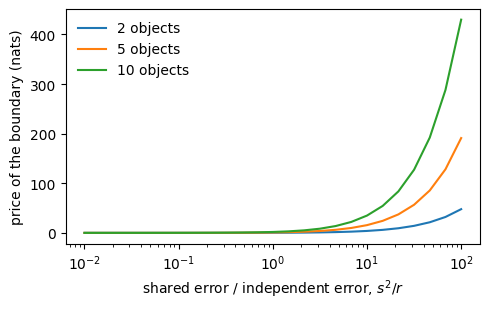

price at s2/r = 4: {2: 1.27, 5: 5.12, 10: 11.37}
3 objects, 10/40/160 frames: [2.56, 2.56, 2.56]


In [9]:
def kl_gauss(mu1, S1, mu2, S2):
    k, S2inv, d = len(mu1), np.linalg.inv(S2), mu2 - mu1
    return 0.5 * (np.trace(S2inv @ S1) + d @ S2inv @ d - k + np.linalg.slogdet(S2)[1] - np.linalg.slogdet(S1)[1])


def price(rng, ratio, n, r=R_SIGHT, frames=20):
    """Price in nats of the agents' product of marginals against the exact posterior."""
    theta = np.linspace(1.0, 4.0, n)
    z = sample_z(rng, r, ratio * r, frames, theta)
    mu_x, Sig_x = exact_posterior(z, r, ratio * r)
    mu_a, v_a = agent_optimum(z, r, ratio * r)
    return kl_gauss(mu_a, np.diag(v_a), mu_x, Sig_x)


# the identity: F(q) - F(exact) is the KL
kl = kl_gauss(mu_a, np.diag(v_a), mu_x, Sig_x)
dF = F_global(mu_a, np.diag(v_a), z, R_SIGHT, S_FRAME) - F_global(mu_x, Sig_x, z, R_SIGHT, S_FRAME)
print(f"KL = {kl:.4f} nats   F(agents) - F(exact) = {dF:.4f} nats")
assert np.isclose(kl, dF, atol=1e-6)

RATIOS = np.logspace(-2, 2, 25)
PRICES = {n: [np.mean([price(rng, a, n) for _ in range(20)]) for a in RATIOS] for n in (2, 5, 10)}
fig, ax = plt.subplots(figsize=(5, 3.2))
for n, p in PRICES.items():
    ax.semilogx(RATIOS, p, label=f"{n} objects")
ax.set_xlabel("shared error / independent error, $s^2/r$"); ax.set_ylabel("price of the boundary (nats)")
ax.legend(frameon=False); fig.tight_layout(); plt.show()
PRICE_AT_4 = {n: np.mean([price(rng, S_FRAME / R_SIGHT, n) for _ in range(40)]) for n in (2, 5, 10)}
PRICE_FRAMES = [np.mean([price(rng, S_FRAME / R_SIGHT, 3, frames=f) for _ in range(40)]) for f in (10, 40, 160)]
print("price at s2/r = 4:", {k: round(float(v), 2) for k, v in PRICE_AT_4.items()})
print("3 objects, 10/40/160 frames:", [round(float(v), 2) for v in PRICE_FRAMES])

The price grows with the shared error and with the number of objects, and it does not fall with
more frames: more data sharpens each belief but cannot restore a correlation the factorisation
has no place to hold. It is the information the objects carry about each other. Every boundary
between processes is a conditional-independence assumption, and it has a price you can compute.

## D. No thresholds

The robot drives past an object along a straight line ($x_t$ from $-8$ to $8$ m), at lateral
distance $\ell$, and measures $\ell$ with a noise that grows with range:

$$ \sigma(\rho) = 0.02\,\big(1+(\rho/2)^2\big)\ \text{m}. $$

The classical move is a **gate**: "ignore detections beyond $k$ metres". Complete both estimators.
`gated` averages the sightings closer than $k$, and returns the prior guess 3.0 m when none
qualifies. `weighted` uses every sighting, with precision $1/\sigma(\rho)^2$.

lateral 1 m: best gate 2.00 m, rmse 1.01 cm;  precision 0.86 cm
lateral 6 m: best gate 8.00 m, rmse 4.79 cm;  precision 4.22 cm


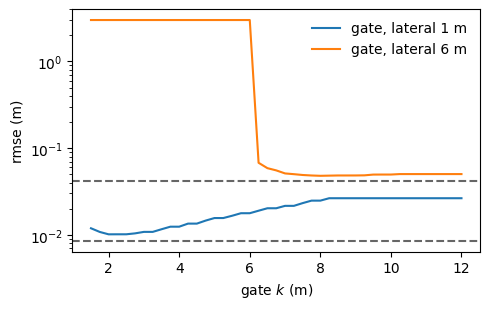

the gate tuned on the near pass, used on the far pass: rmse 300.0 cm


In [10]:
T_FRAMES, X_PATH = 41, np.linspace(-8.0, 8.0, 41)
GATES = np.linspace(1.5, 12.0, 43)


def sig_range(rho):
    return 0.02 * (1.0 + (rho / 2.0) ** 2)


def sightings(rng, lateral, trials=4000):
    rho = np.hypot(X_PATH, lateral)
    return rho, lateral + rng.normal(size=(trials, T_FRAMES)) * sig_range(rho)


def gated(y, rho, k, prior=3.0):
    m = rho < k
    return y[:, m].mean(axis=1) if m.any() else np.full(len(y), prior)


def weighted(y, rho):
    w = 1.0 / sig_range(rho) ** 2
    return (y * w).sum(axis=1) / w.sum()


GATE_RMSE, WEIGHTED_RMSE = {}, {}
fig, ax = plt.subplots(figsize=(5, 3.2))
for lateral in (1.0, 6.0):
    rho, y = sightings(rng, lateral)
    GATE_RMSE[lateral] = np.array([np.sqrt(np.mean((gated(y, rho, k) - lateral) ** 2)) for k in GATES])
    WEIGHTED_RMSE[lateral] = float(np.sqrt(np.mean((weighted(y, rho) - lateral) ** 2)))
    ax.semilogy(GATES, GATE_RMSE[lateral], label=f"gate, lateral {lateral:.0f} m")
    ax.axhline(WEIGHTED_RMSE[lateral], ls="--", color="0.4")
    best = GATES[np.argmin(GATE_RMSE[lateral])]
    print(f"lateral {lateral:.0f} m: best gate {best:.2f} m, rmse {GATE_RMSE[lateral].min() * 100:.2f} cm;"
          f"  precision {WEIGHTED_RMSE[lateral] * 100:.2f} cm")
ax.set_xlabel("gate $k$ (m)"); ax.set_ylabel("rmse (m)"); ax.legend(frameon=False); fig.tight_layout(); plt.show()
BEST_1 = float(GATES[np.argmin(GATE_RMSE[1.0])])
BEST_6 = float(GATES[np.argmin(GATE_RMSE[6.0])])
CROSS = float(GATE_RMSE[6.0][np.argmin(np.abs(GATES - BEST_1))])
print(f"the gate tuned on the near pass, used on the far pass: rmse {CROSS * 100:.1f} cm")

Answer in the notebook:
1. Why is the curve U-shaped on the near pass?
2. Which gate would you ship, without knowing which pass the robot will make?
3. What had to be known for `weighted` to work, and where would it fail?

1. A small gate throws away useful sightings; a large one lets in sightings that are far noisier
   than the rest but count the same. 2. None: the best gate on one scene returns no sightings at all
   on the other. 3. It needs $\sigma(\rho)$, a model of how the sensor degrades. That is the
   modelling the gate was postponing. A wrong $\sigma(\rho)$ is a wrong model, and Day 3 shows how
   to test one with NEES; a gate gives you nothing to test.

## E. The gate that survives

Variances handle errors that average out. Now take a run of $n$ frames that all share **one bias**
$b$ (the robot's motion smears consecutive frames in the same direction). With prior precision
$\Lambda_0$ and frame precision $\Lambda$ multiplied by an attenuation $\alpha$, the mean is
displaced by

$$ \Delta\mu_n = \frac{n\alpha\Lambda}{\Lambda_0 + n\alpha\Lambda}\, b . $$

Complete `displacement`, then check it by running the recursive update on biased frames. Plot it
for $\alpha = 1, 0.3, 0.05, 0$. What does attenuation change, and what does it not change?

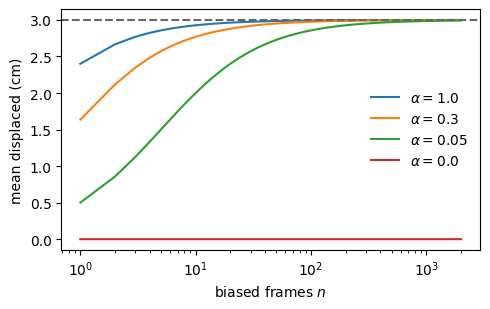

{1.0: 3.0, 0.3: 3.0, 0.05: 2.99, 0.0: 0.0}


In [11]:
LAM0, LAM, BIAS = 1.0 / 0.10 ** 2, 1.0 / 0.05 ** 2, 0.03
N_FRAMES = np.arange(0, 2001)
ALPHAS = (1.0, 0.3, 0.05, 0.0)


def displacement(n, alpha, lam0=LAM0, lam=LAM, b=BIAS):
    return n * alpha * lam / (lam0 + n * alpha * lam) * b


def recursive(n, alpha):
    mu, info = 0.0, LAM0
    for _ in range(n):
        gain = alpha * LAM / (info + alpha * LAM)
        mu += gain * (BIAS - mu)
        info += alpha * LAM
    return mu


for a in ALPHAS[:-1]:
    assert np.isclose(displacement(200, a), recursive(200, a))
fig, ax = plt.subplots(figsize=(5, 3.2))
for a in ALPHAS:
    ax.semilogx(N_FRAMES[1:], displacement(N_FRAMES[1:], a) * 100, label=rf"$\alpha={a}$")
ax.axhline(BIAS * 100, color="0.4", ls="--")
ax.set_xlabel("biased frames $n$"); ax.set_ylabel("mean displaced (cm)"); ax.legend(frameon=False)
fig.tight_layout(); plt.show()
print({a: round(float(displacement(2000, a)) * 100, 2) for a in ALPHAS})

Attenuation changes the rate and not the limit: for every $\alpha>0$ the mean ends displaced by the
whole of $b$. Only $\alpha=0$, a gate, bounds it. So the rule is not "never a gate": it is that a
gate must be declared and justified, and the justification here is that the model has no coordinate
for a bias shared across frames.